## LISAresponse accuracy analysis

This notebook investigates the accuracy of monochromatic waveforms for different tiling setups, to visualise the effects of the various approximations present in the package. 

We also explain the presence of the off-bin effect, with signals not localised to a specific bin performing worse than on bin sources. 

In [1]:
# Imports, the plot style, and the numbers every section below shares.
import time

import jax
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits

import WDM
from WDM_LISAresponse import LISAresponse
from WDM_LISAresponse.code.waveforms import waveforms
from WDM_LISAresponse.code.utils import utils

DT = 10.0                                   # sample cadence [s]
N_SIGNAL = int(waveforms.YRSID_SI // DT)    # one year of samples
TUKEY_ALPHA = 0.05                          # about 9 days of taper at each end
THETA, PHI = np.pi / 3, np.pi / 6           # sky position, as in getting_started
LINK = utils.Link(1, 2)
MAX_LAG = 25
NUM_INTEGRAL_POINTS = 40                    # trapezoid nodes in the time-domain reference

# Two SNR-100 signals are distinguishable above a mismatch of 1/(2 SNR^2).
SNR = 100
THRESHOLD = 1 / (2 * SNR ** 2)

# One colour per source, the same in every figure. The tones take the first three
# slots of a colour-blind-safe categorical palette; the EMRI is dark ink.
COLOURS = {"1 mHz": "#2a78d6", "5 mHz": "#eb6834", "10 mHz": "#1baf7a", "EMRI": "#2b2b2b"}
INK, MUTED, HAIRLINE, SHADE = "#52514e", "#898781", "#e1e0d9", "#f3f2ee"

data = read_orbit_file("esa-trailing-orbits.h5")
orbit_times = data.t0 + data.dt * np.arange(data.size)
orbits = InterpolatedOrbits(orbit_times, data.positions, data.velocities)

# The signal starts 200 days into the orbit file: the widest tiling below pads
# 162 days ahead of it, and every grid has to lie inside the orbits.
START = orbit_times[0] + 200 * 86400.0
signal_times = START + DT * np.arange(N_SIGNAL)

## Investigated Waveforms 

We consider 3 monochromatic waveforms at different frequencies, and and EMRI, as that is a physically relevat signal.

In [2]:
# The three monochromatic sources, at 1, 5 and 10 mHz, with equal amplitudes in
# both polarisations.
FREQUENCIES = {"1 mHz": 1.0e-3, "5 mHz": 5.0e-3, "10 mHz": 1.0e-2}


def monochromatic(f):
    _, h_plus, h_cross = waveforms.generate_windowed_waveform(
        "monochromatic", t0=START, dt=DT, N=N_SIGNAL,
        model_kwargs=dict(A_plus=1.0e-21, A_cross=1.0e-21, f=f, phi_0=0.0),
        window_function="tukey", window_kwargs=dict(alpha=TUKEY_ALPHA))
    return h_plus, h_cross


signals = {name: monochromatic(f) for name, f in FREQUENCIES.items()}

The EMRI comes from FEW through `waveforms.emri_generator`, which memory-maps FEW's 5 GB amplitude table instead of reading it, so it needs about 1.5 GB. Building the generator is the slow step, so it has a cell of its own and is reused when the notebook is re-run.

In [3]:
# About ten seconds; re-running the cell reuses the generator.
if "td_gen" not in globals():
    td_gen = waveforms.emri_generator()

In [4]:
EMRI_PARAMS = dict(
    m1=1.0e6, m2=10.0, a=0.9, p0=12.0, e0=0.3, x0=1.0,
    dist=1.0, theta=THETA, phi=PHI,
    qK=np.pi / 3, phiK=np.pi / 3,
    Phi_phi0=np.pi / 3, Phi_theta0=0.0, Phi_r0=np.pi / 3,
    eps=1.0e-2,
)
_, h_plus, h_cross = waveforms.generate_windowed_waveform(
    "emri", t0=START, dt=DT, N=N_SIGNAL,
    model_kwargs=dict(td_gen=td_gen, **EMRI_PARAMS),
    window_function="tukey", window_kwargs=dict(alpha=TUKEY_ALPHA))
signals["EMRI"] = (h_plus, h_cross)

# Where the EMRI's power sits, which decides how much of it the m = 0 band
# takes on the coarsest frequency grids.
power = np.abs(np.fft.rfft(signals["EMRI"][0])) ** 2
cumulative = np.cumsum(power) / power.sum()
f_low, f_high = np.fft.rfftfreq(N_SIGNAL, DT)[np.searchsorted(cumulative, [0.01, 0.99])]
print(f"98% of the EMRI's power lies between {f_low * 1e3:.2f} and {f_high * 1e3:.2f} mHz")

98% of the EMRI's power lies between 0.81 and 3.14 mHz


## TD reference responses

We compute the reference response for the link $1 \rightarrow 2$, as all 6 links are characterised by fairly similar behaviours. 

Every tiling below pads the record differently, so the reference is computed once per waveform, on a record with a few hours of zeros at each end, and `utils.apply_repadding` moves it onto each tiling's grid. The response reaches at most ~500 s past the signal, so nothing is lost: on a 30-day test this agreed with computing the reference on each grid directly to $10^{-11}$, and `apply_repadding` refuses any crop that would drop a non-zero sample.


In [5]:
# The reference grid: 16 rows of 64 samples (2.8 h) of zeros at each end, which
# holds everything the response carries past the signal.
REF_NF = 64
ref_info = utils.wdm_padding_info(N_SIGNAL, REF_NF, extra_rows_left=16, extra_rows_right=16)
ref_response = LISAresponse(
    WDM.WDM.WDM_transform(dt=DT, Nf=REF_NF, N=ref_info["target_length"]), orbits,
    t0=START - ref_info["pad_left"] * DT, max_lag_L=MAX_LAG, link_convention=(LINK,))


def time_domain_reference(response, info, h_plus, h_cross):
    """Time-domain link response on the grid ``info`` describes."""
    _, h_plus, h_cross = utils.apply_zero_padding(
        signal_times, h_plus, h_cross, info["pad_left"], info["pad_right"])
    return np.asarray(response.one_arm_response_time_domain(
        THETA, PHI, h_plus, h_cross, link=LINK, num_integral_points=NUM_INTEGRAL_POINTS))


references = {}
for name, (h_plus, h_cross) in signals.items():
    start = time.perf_counter()
    references[name] = time_domain_reference(ref_response, ref_info, h_plus, h_cross)
    print(f"{name:>6}: {time.perf_counter() - start:.1f} s")

 1 mHz: 4.8 s
 5 mHz: 4.4 s
10 mHz: 4.3 s
  EMRI: 4.1 s


## WDM tilings

In [6]:
# Delta T = Nf dt from 10^2 to 10^6 s, eight tilings per decade. Nf need not be a
# power of two, only even, which WDM_transform requires. The widest tiling pads
# the year to about 700 days, N = 6e6 samples.
NF = np.unique(2 * np.round(np.logspace(2, 6, 33) / (2 * DT)).astype(int))
DELTA_T = NF * DT

print(f"{'Nf':>7} {'dT [s]':>9} {'dF [mHz]':>9} {'Nt':>7} {'grid [d]':>9}")
for Nf in NF:
    info = utils.wdm_padding_info(N_SIGNAL, Nf, max_lag_L=MAX_LAG)
    print(f"{Nf:>7} {Nf * DT:>9.3g} {1e3 / (2 * Nf * DT):>9.3g} {info['Nt']:>7} "
          f"{info['target_length'] * DT / 86400:>9.0f}")

     Nf    dT [s]  dF [mHz]      Nt  grid [d]
     10       100         5  315610       365
     14       140      3.57  225444       365
     18       180      2.78  175350       365
     24       240      2.08  131520       365
     32       320      1.56   98648       365
     42       420      1.19   75166       365
     56       560     0.893   56382       365
     74       740     0.676   42674       365
    100     1e+03       0.5   31586       366
    134  1.34e+03     0.373   23578       366
    178  1.78e+03     0.281   17758       366
    238  2.38e+03      0.21   13288       366
    316  3.16e+03     0.158   10014       366
    422  4.22e+03     0.118    7506       367
    562  5.62e+03     0.089    5644       367
    750   7.5e+03    0.0667    4236       368
   1000     1e+04      0.05    3184       369
   1334  1.33e+04    0.0375    2394       370
   1778  1.78e+04    0.0281    1802       371
   2372  2.37e+04    0.0211    1358       373
   3162  3.16e+04    0.0158    102

In [7]:
def build_tiling(Nf):
    """Padding plan, transform and response for one tiling."""
    info = utils.wdm_padding_info(N_SIGNAL, Nf, max_lag_L=MAX_LAG,
                                  taper_samples=waveforms.tukey_taper_samples(N_SIGNAL, TUKEY_ALPHA))
    wdm = WDM.WDM.WDM_transform(dt=DT, Nf=int(Nf), N=info["target_length"])
    response = LISAresponse(wdm, orbits, t0=START - info["pad_left"] * DT,
                            max_lag_L=MAX_LAG, link_convention=(LINK,))
    return info, wdm, response


def mismatch(info, wdm, response, h_plus, h_cross, reference):
    """Wavelet response against a time-domain reference on the same grid,
    compared on the rows the signal occupies at full amplitude."""
    _, h_plus, h_cross = utils.apply_zero_padding(
        signal_times, h_plus, h_cross, info["pad_left"], info["pad_right"])
    ours = response.one_arm_response(THETA, PHI, wdm.dwt(h_plus), wdm.dwt(h_cross), link=LINK)
    cut = utils.wdm_cut_info(info)
    return utils.wdm_mismatch(utils.apply_wdm_cut(np.asarray(ours), cut),
                              utils.apply_wdm_cut(np.asarray(wdm.dwt(reference)), cut))["mismatch"]


sweep = {name: np.full(len(NF), np.nan) for name in signals}
for i, Nf in enumerate(NF):
    start = time.perf_counter()
    info, wdm, response = build_tiling(Nf)
    for name, (h_plus, h_cross) in signals.items():
        reference = utils.apply_repadding(references[name], ref_info["pad_left"], ref_info["pad_right"],
                                          info["pad_left"], info["pad_right"])
        sweep[name][i] = mismatch(info, wdm, response, h_plus, h_cross, reference)
    # Every tiling compiles for its own array shapes and none are reused, so let
    # the compiled code go rather than accumulate it.
    jax.clear_caches()
    print(f"Nf = {Nf:>6}, dT = {Nf * DT:8.3g} s:  "
          + "  ".join(f"{name} {sweep[name][i]:.1e}" for name in signals)
          + f"   ({time.perf_counter() - start:.1f} s)")

Nf =     10, dT =      100 s:  1 mHz 1.0e+00  5 mHz 3.5e-09  10 mHz 3.7e-09  EMRI 5.9e-01   (7.2 s)
Nf =     14, dT =      140 s:  1 mHz 1.0e+00  5 mHz 1.8e-06  10 mHz 9.2e-07  EMRI 2.0e-01   (7.7 s)
Nf =     18, dT =      180 s:  1 mHz 6.8e-01  5 mHz 1.5e-07  10 mHz 4.5e-06  EMRI 7.6e-02   (5.6 s)
Nf =     24, dT =      240 s:  1 mHz 4.1e-01  5 mHz 8.2e-07  10 mHz 3.0e-07  EMRI 2.6e-03   (5.9 s)
Nf =     32, dT =      320 s:  1 mHz 1.1e-05  5 mHz 4.0e-08  10 mHz 2.4e-06  EMRI 1.1e-02   (5.1 s)
Nf =     42, dT =      420 s:  1 mHz 6.0e-09  5 mHz 2.5e-08  10 mHz 2.6e-06  EMRI 3.1e-07   (4.9 s)
Nf =     56, dT =      560 s:  1 mHz 3.9e-09  5 mHz 1.0e-06  10 mHz 5.7e-08  EMRI 2.5e-07   (6.4 s)
Nf =     74, dT =      740 s:  1 mHz 4.8e-07  5 mHz 1.4e-06  10 mHz 3.6e-08  EMRI 5.7e-08   (5.6 s)
Nf =    100, dT =    1e+03 s:  1 mHz 3.6e-09  5 mHz 3.6e-09  10 mHz 3.5e-09  EMRI 2.6e-08   (5.1 s)
Nf =    134, dT = 1.34e+03 s:  1 mHz 3.1e-08  5 mHz 4.4e-06  10 mHz 1.5e-08  EMRI 1.3e-07   (7.8 s)


## Tiling Plot

The shaded region is where the two responses would be distinguishable at SNR 100, above a mismatch of $1/(2\,\mathrm{SNR}^2) = 5\times10^{-5}$. The comparison drops the $m = 0$ band, which the transform gets wrong without `calc_m0`, so a tone whose nearest band is $m = 0$ (below $\Delta F/2$) is compared on its leakage into the bands above only. Those points are hollow.


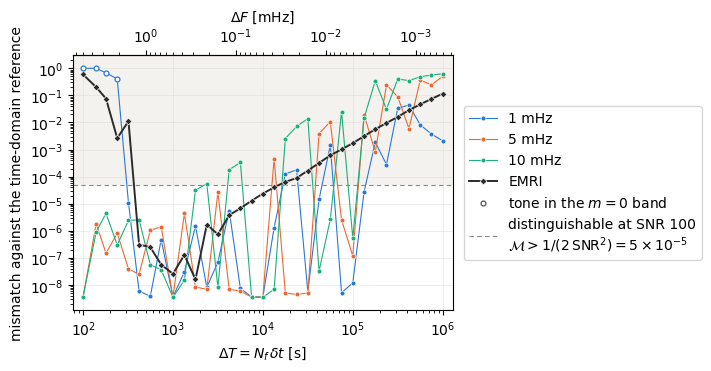

In [8]:
MARKERS = dict(ms=3.5, mec="white", mew=0.5)


def power_of_ten(x):
    exponent = int(np.floor(np.log10(x)))
    return rf"{x / 10 ** exponent:.0f}\times10^{{{exponent}}}"


def distinguishable(ax, top):
    """Shade the region an SNR-100 analysis could tell apart; return its legend entry."""
    ax.axhspan(THRESHOLD, top, color=SHADE, lw=0, zorder=0)
    line = ax.axhline(THRESHOLD, color=MUTED, lw=0.8, ls=(0, (4, 3)), zorder=1)
    return line, (f"distinguishable at SNR {SNR}\n"
                  rf"$\mathcal{{M}} > 1/(2\,\mathrm{{SNR}}^2) = {power_of_ten(THRESHOLD)}$")


def mismatch_limits(values):
    values = np.concatenate([np.ravel(v) for v in values])
    top = min(3.0, max(10 * THRESHOLD, 3 * np.nanmax(values)))
    return np.nanmin(values) / 3, top


fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
bottom, top = mismatch_limits(sweep.values())
threshold_entry = distinguishable(ax, top)

for name, values in sweep.items():
    if name == "EMRI":
        ax.plot(DELTA_T, values, color=COLOURS[name], lw=1.4, marker="D", zorder=4,
                label=name, **MARKERS)
        continue
    ax.plot(DELTA_T, values, color=COLOURS[name], lw=0.8, marker="o", zorder=3,
            label=name, **MARKERS)
    in_m0 = FREQUENCIES[name] < 1 / (4 * DELTA_T)          # f < Delta F / 2
    ax.plot(DELTA_T[in_m0], values[in_m0], ls="none", marker="o", ms=3.5,
            mfc="white", mec=COLOURS[name], mew=0.9, zorder=5)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], ls="none", marker="o", ms=3.5, mfc="white", mec=INK, mew=0.9))
labels.append("tone in the $m = 0$ band")
handles.append(threshold_entry[0])
labels.append(threshold_entry[1])
ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1.01, 0.5))

ax.set(xscale="log", yscale="log", ylim=(bottom, top),
       xlim=(DELTA_T[0] / 1.3, DELTA_T[-1] * 1.3),
       xlabel=r"$\Delta T = N_f\,\delta t$ [s]", ylabel="mismatch against the time-domain reference")
ax.grid(color=HAIRLINE, lw=0.4)
ax.set_axisbelow(True)

# Delta F on top: the same axis read the other way, Delta F Delta T = 1/2.
def reciprocal_mhz(x):
    """Delta F in mHz from Delta T in s, and back: the map is its own inverse."""
    with np.errstate(divide="ignore"):
        return 5e2 / np.asarray(x, dtype=float)


top_axis = ax.secondary_xaxis("top", functions=(reciprocal_mhz, reciprocal_mhz))
top_axis.set_xlabel(r"$\Delta F$ [mHz]")
plt.show()

## Off-Bin Behaviour

From the plot above, we can see significant variation for the monochromatic signal, this is due to the fact, that the accuracy of the method heavily depends on whether the signal is on bin or off bin.

In [9]:
# The most accurate tiling: the lowest geometric-mean mismatch over the four
# waveforms - geometric, because the mismatches span many decades.
score = np.exp(np.mean(np.log([sweep[name] for name in signals]), axis=0))
NF_BEST = int(NF[np.nanargmin(score)])
print(f"most accurate tiling: Nf = {NF_BEST}, Delta T = {NF_BEST * DT:.0f} s")

info, wdm, response = build_tiling(NF_BEST)
R = np.linspace(0.0, 1.0, 21)
M_BIN = {name: int(round(f / wdm.dF)) for name, f in FREQUENCIES.items()}

off_bin = {name: np.full(len(R), np.nan) for name in FREQUENCIES}
for name in FREQUENCIES:
    start = time.perf_counter()
    for i, r in enumerate(R):
        h_plus, h_cross = monochromatic((M_BIN[name] + r) * wdm.dF)
        # One tiling only, so the reference is computed on its grid directly.
        reference = time_domain_reference(response, info, h_plus, h_cross)
        off_bin[name][i] = mismatch(info, wdm, response, h_plus, h_cross, reference)
    print(f"{name:>6}: m = {M_BIN[name]}, {time.perf_counter() - start:.0f} s")

most accurate tiling: Nf = 100, Delta T = 1000 s
 1 mHz: m = 2, 99 s
 5 mHz: m = 10, 97 s
10 mHz: m = 20, 98 s


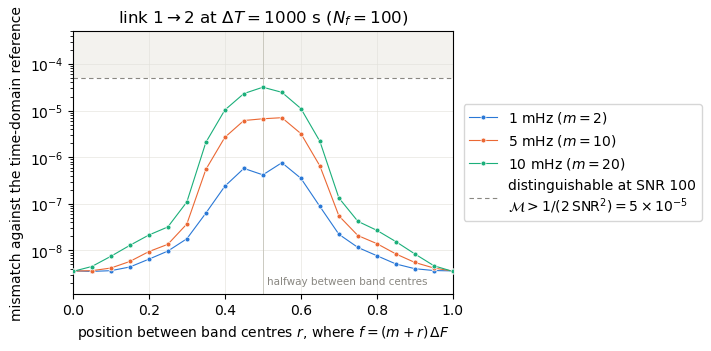

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
bottom, top = mismatch_limits(off_bin.values())
threshold_entry = distinguishable(ax, top)

# r = 1/2 is halfway between the centres of bands m and m + 1, as far as a
# tone can sit from any band centre: its power splits equally between the two.
ax.axvline(0.5, color="#c3c2b7", lw=0.6, zorder=1)
ax.text(0.51, bottom * 1.6, "halfway between band centres", color=MUTED, fontsize=7.5)

for name, values in off_bin.items():
    ax.plot(R, values, color=COLOURS[name], lw=0.8, marker="o", zorder=3,
            label=rf"{name} ($m = {M_BIN[name]}$)", **MARKERS)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles + [threshold_entry[0]], labels + [threshold_entry[1]],
          loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set(yscale="log", xlim=(0, 1), ylim=(bottom, top),
       xlabel=r"position between band centres $r$, where $f = (m + r)\,\Delta F$",
       ylabel="mismatch against the time-domain reference",
       title=rf"link $1 \rightarrow 2$ at $\Delta T = {NF_BEST * DT:.0f}$ s ($N_f = {NF_BEST}$)")
ax.grid(color=HAIRLINE, lw=0.4)
ax.set_axisbelow(True)
plt.show()

### Where the off-bin error comes from

It is not the band-centre frequency in the response: giving every pixel the tone's true frequency instead changes the off-bin mismatch by a few percent at most. It comes from the variable time shift. For a constant delay the shift is essentially exact at every position between band centres, but the orbital delay changes from row to row and the shift applies one delay per row. A tone split between two bands is sensitive to that; a tone on a band centre is not. At 5 and 10 mHz the error grows as the square of the delay's rate of change.

At $\Delta T = 1000$ s every tone here stays below the SNR-100 threshold, 10 mHz by a factor of 1.6, so higher frequencies, higher SNR or a coarser tiling can be expected to cross it. Removing the error needs a term in the delay's rate of change inside the shift, with filter tables of its own, which is not implemented; see `response_sub.apply_batch_shift`.